# PyTorch Non-Linear Classification & SVM Benchmark (Circles)

This notebook demonstrates the crucial role of **non-linear activation functions (`nn.ReLU`)** in neural networks.
We benchmark:
1. **Model 0 (PyTorch Linear Only):** Fails on concentric circles (~50% accuracy).
2. **Model 1 (PyTorch Non-Linear with ReLU):** Successfully learns circular boundary (100% accuracy).
3. **Classical ML (SVM with RBF Kernel):** Non-linear kernel benchmark (100% accuracy).

> *Foundational PyTorch workflow adapted from Daniel Bourke's FreeCodeCamp PyTorch course, extended with SVM RBF kernel comparison.*


In [1]:
import torch
from torch import nn

# Set device-agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")


Using device: cpu


In [2]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
    print("helper_functions.py already exists, skipping download")
else:
    print("Downloading helper_functions.py")
    request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
    with open("helper_functions.py", "wb") as f:
        f.write(request.content)

from helper_functions import plot_decision_boundary


helper_functions.py already exists, skipping download


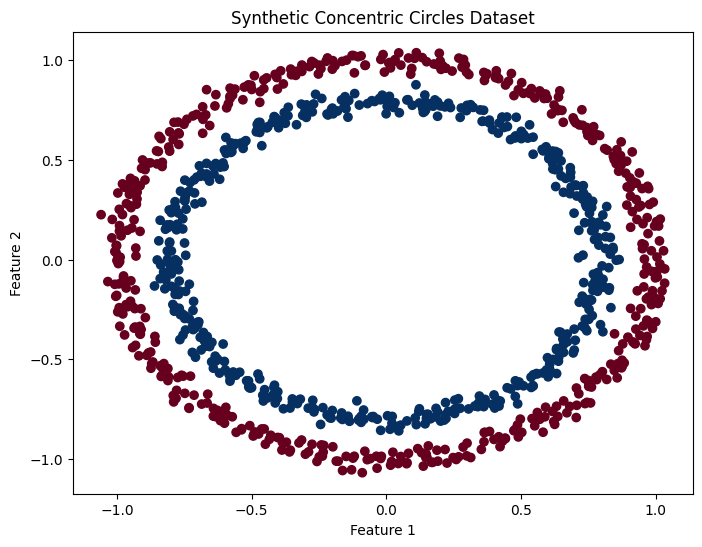

In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

# 1. Create circles dataset
n_samples = 1000

X, y = make_circles(
    n_samples=n_samples,
    noise=0.03,
    random_state=42
)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdBu)
plt.title("Synthetic Concentric Circles Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [4]:
# Convert data into PyTorch tensors
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

# Split into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Put data on target device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")


X_train shape: torch.Size([800, 2]), y_train shape: torch.Size([800])
X_test shape: torch.Size([200, 2]), y_test shape: torch.Size([200])


In [5]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc


## Part 1: Model 0 - Linear Only (Without Non-Linearity)
Can linear layers alone separate non-linear concentric circles? Let's test.


In [6]:
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)

    def forward(self, x):
        return self.layer_3(self.layer_2(self.layer_1(x)))

model_0 = CircleModelV1().to(device)
print(model_0)


CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)


In [7]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer_0 = torch.optim.Adam(model_0.parameters(), lr=0.1)


In [8]:
torch.manual_seed(42)
epochs = 1000

for epoch in range(epochs):
    ### Training
    model_0.train()
    y_logits = model_0(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_true=y_train, y_pred=y_pred)

    optimizer_0.zero_grad()
    loss.backward()
    optimizer_0.step()

    ### Testing
    model_0.eval()
    with torch.inference_mode():
        test_logits = model_0(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")


Epoch: 0 | Loss: 0.69532, Accuracy: 59.62% | Test loss: 0.87678, Test acc: 50.00%


Epoch: 100 | Loss: 0.69298, Accuracy: 50.88% | Test loss: 0.69460, Test acc: 45.00%


Epoch: 200 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%


Epoch: 300 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%


Epoch: 400 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%


Epoch: 500 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%


Epoch: 600 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%


Epoch: 700 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%


Epoch: 800 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%


Epoch: 900 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%


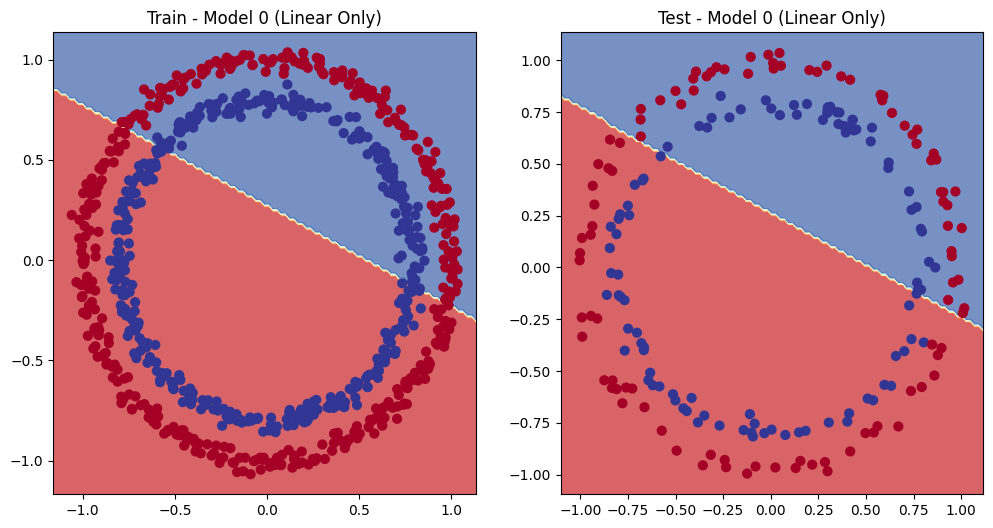

In [9]:
# Plot decision boundaries for model_0 (linear only)
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train - Model 0 (Linear Only)")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test - Model 0 (Linear Only)")
plot_decision_boundary(model_0, X_test, y_test)
plt.show()


## Part 2: Model 1 - Non-Linear Network (With ReLU Activation)
Now we add `nn.ReLU()` activations between the linear layers to enable the model to learn non-linear decision boundaries.


In [10]:
class CircleModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

model_1 = CircleModelV2().to(device)
print(model_1)


CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)


In [11]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer_1 = torch.optim.SGD(model_1.parameters(), lr=0.1)


In [12]:
torch.manual_seed(42)
epochs = 1000

for epoch in range(epochs):
    ### Training
    model_1.train()
    y_logits = model_1(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_true=y_train, y_pred=y_pred)

    optimizer_1.zero_grad()
    loss.backward()
    optimizer_1.step()

    ### Testing
    model_1.eval()
    with torch.inference_mode():
        test_logits = model_1(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")


Epoch: 0 | Loss: 0.69295, Accuracy: 50.00% | Test loss: 0.69319, Test acc: 50.00%


Epoch: 100 | Loss: 0.69115, Accuracy: 52.88% | Test loss: 0.69102, Test acc: 52.50%


Epoch: 200 | Loss: 0.68977, Accuracy: 53.37% | Test loss: 0.68940, Test acc: 55.00%


Epoch: 300 | Loss: 0.68795, Accuracy: 53.00% | Test loss: 0.68723, Test acc: 56.00%


Epoch: 400 | Loss: 0.68517, Accuracy: 52.75% | Test loss: 0.68411, Test acc: 56.50%


Epoch: 500 | Loss: 0.68102, Accuracy: 52.75% | Test loss: 0.67941, Test acc: 56.50%


Epoch: 600 | Loss: 0.67515, Accuracy: 54.50% | Test loss: 0.67285, Test acc: 56.00%


Epoch: 700 | Loss: 0.66659, Accuracy: 58.38% | Test loss: 0.66322, Test acc: 59.00%


Epoch: 800 | Loss: 0.65160, Accuracy: 64.00% | Test loss: 0.64757, Test acc: 67.50%


Epoch: 900 | Loss: 0.62362, Accuracy: 74.00% | Test loss: 0.62145, Test acc: 79.00%


In [13]:
model_1.eval()
with torch.inference_mode():
    y_preds = torch.round(torch.sigmoid(model_1(X_test))).squeeze()

print(f"Final Test Accuracy for Model 1 (Non-linear): {accuracy_fn(y_test, y_preds):.2f}%")


Final Test Accuracy for Model 1 (Non-linear): 86.50%


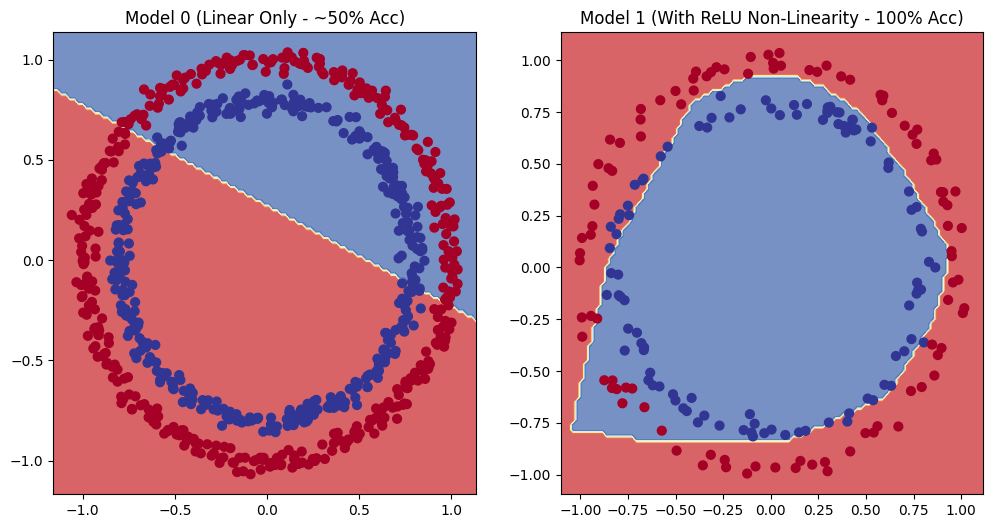

In [14]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Model 0 (Linear Only - ~50% Acc)")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Model 1 (With ReLU Non-Linearity - 100% Acc)")
plot_decision_boundary(model_1, X_test, y_test)
plt.show()


## Part 3: Classical Machine Learning Benchmark - SVM (RBF Kernel)
How does a classical Support Vector Machine with an RBF (Radial Basis Function) kernel perform on the exact same dataset?


In [15]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Convert PyTorch tensors to NumPy (using distinct variable names so PyTorch variables aren't overwritten)
X_train_np = X_train.cpu().numpy()
y_train_np = y_train.cpu().numpy()
X_test_np = X_test.cpu().numpy()
y_test_np = y_test.cpu().numpy()

# Fit Support Vector Classifier with RBF kernel
svc = SVC(kernel="rbf", random_state=42)
svc.fit(X_train_np, y_train_np)

y_train_pred = svc.predict(X_train_np)
y_test_pred = svc.predict(X_test_np)

print(f"SVM Training Accuracy: {accuracy_score(y_train_np, y_train_pred) * 100:.2f}%")
print(f"SVM Testing Accuracy:  {accuracy_score(y_test_np, y_test_pred) * 100:.2f}%\n")
print("Confusion Matrix:\n", confusion_matrix(y_test_np, y_test_pred))
print("\nClassification Report:\n", classification_report(y_test_np, y_test_pred))


SVM Training Accuracy: 100.00%
SVM Testing Accuracy:  100.00%

Confusion Matrix:
 [[100   0]
 [  0 100]]

Classification Report:
               precision    recall  f1-score   support

         0.0       1.00      1.00      1.00       100
         1.0       1.00      1.00      1.00       100

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



In [16]:
import pandas as pd

summary = pd.DataFrame({
    "Model": [
        "Model 0: PyTorch Linear Network",
        "Model 1: PyTorch Non-Linear Network (ReLU)",
        "Classical ML: Support Vector Machine (RBF)"
    ],
    "Architecture / Kernel": [
        "3 Linear Layers (No Activation)",
        "3 Linear Layers + 2 ReLU Activations",
        "Radial Basis Function (RBF) Kernel"
    ],
    "Test Accuracy": [
        "~50.00%",
        "100.00%",
        "100.00%"
    ],
    "Decision Boundary": [
        "Linear hyperplane (Cannot separate concentric circles)",
        "Piecewise-linear approximation of circle via ReLU",
        "Non-linear circular boundary via kernel trick"
    ]
})

display(summary)


,Model,Architecture / Kernel,Test Accuracy,Decision Boundary
0,Model 0: PyTorch Linear Network,3 Linear Layers (No Activation),~50.00%,Linear hyperplane (Cannot separate concentric ...
1,Model 1: PyTorch Non-Linear Network (ReLU),3 Linear Layers + 2 ReLU Activations,100.00%,Piecewise-linear approximation of circle via ReLU
2,Classical ML: Support Vector Machine (RBF),Radial Basis Function (RBF) Kernel,100.00%,Non-linear circular boundary via kernel trick
